# Frozen fold3 LightGBM + isotonic/linear: desktop inference

Install requirements.txt in this folder using Python3.12. Open this notebook with that environment. This notebook uses only files in this folder; it does not refit any model. Target is next-bar trailing MA5 price. REST_2025 is an in-training retrospective backcast; DEV fits calibrators; OOT1 is their later evaluation; REST_2026 mixes other historical roles—inspect provenance. All previously inspected results are development evidence.

In [1]:
from pathlib import Path
import sys,json,pickle
import pandas as pd
from IPython.display import display,Image
paths=[Path.cwd(),Path.cwd()/'research/mts_gold/training_artifacts/_training_baseline/model1_15m_priceMA/_final_basemod']
package=next(p for p in paths if (p/'prediction_bundle.pkl').exists())
sys.path.insert(0,str(package))
from predict_local import load_models,predict,report
metadata=json.loads((package/'package_metadata.json').read_text())
display(metadata['period_definitions'])
display(metadata['limitations'])

{'ALL': 'All scoreable saved rows; descriptive mix of fitted and later periods',
 'REST_2025': 'Bangkok calendar2025; base-training backcasts, calibration applied retrospectively',
 'DEV': 'Exact fold3 calibration-fit rows, 2026-02-12 to2026-04-21 Bangkok',
 'OOT1': 'Exact fold3 later calibration-evaluation rows, 2026-04-22 to2026-06-26 Bangkok',
 'REST_2026': 'All other2026 context; mixed base-training, embargo and post-fold3 backtest. Use provenance for clean slices'}

['No new market data fetched; latest saved snapshot only.',
 'The original fold3 model used2025 plus early2026 for base training;2025 is not an untouched test.',
 'Calibrators were fitted in2026 and are back-applied to earlier rows. Historical backcasts use parameters estimated later.',
 'OOT1 and later data were already inspected in earlier project analyses; these are development/backtest results, not fresh final tests.',
 'Predictions are next-bar trailing MA5 prices, not spot-return or trading PnL forecasts. Four of five target closes are already known.',
 'Prepared feature CSVs include fold3-seeded historical Z lag; do not refit preprocessing or shift columns again.',
 'Models remain frozen. The notebook loads them and reproduces predictions; retraining a different sample is a new experiment.']

## Load models and prepared data

The 45 feature columns already contain the original causal lags and fold3 EWMA seed. Target scaling, imputers and feature scalers are frozen in the bundle. Avoid recalculating them from the full dataset.

In [2]:
data=pd.read_csv(package/'all_time_X_y_context.csv.gz')
bundle=load_models(package)
predictions=predict(data,bundle)
display(data.groupby(['period','provenance']).size().rename('context_rows'))
display(pd.concat([data[['decision_at','y_ma5','period','provenance']],predictions],axis=1).head(15))
print('All context predictions:',len(predictions))

period     provenance                    
DEV        calibrator_training                4030
OOT1       calibrator_later_evaluation        4001
REST_2025  base_training                     21621
           other_context                      1400
REST_2026  base_embargo_or_boundary             31
           base_training                      2466
           calibration_embargo_or_context       36
           other_context                       657
           post_fold3_backtest                8561
Name: context_rows, dtype: int64

,decision_at,y_ma5,period,provenance,prediction_lightgbm,prediction_isotonic,prediction_linear
0,2024-12-31 17:15:00+00:00,NaN,REST_2025,other_context,51596.445738,65281.333333,55768.073083
1,2024-12-31 17:30:00+00:00,NaN,REST_2025,other_context,51596.445738,65281.333333,55768.073083
2,2024-12-31 17:45:00+00:00,NaN,REST_2025,other_context,42779.047715,65281.333333,48032.363023
3,2024-12-31 18:00:00+00:00,NaN,REST_2025,other_context,42775.102859,65281.333333,48028.902108
4,2024-12-31 18:15:00+00:00,42519.6,REST_2025,base_training,42779.636042,65281.333333,48032.879176
5,2024-12-31 18:30:00+00:00,42514.4,REST_2025,base_training,42775.102859,65281.333333,48028.902108
6,2024-12-31 18:45:00+00:00,42516.0,REST_2025,base_training,42780.896278,65281.333333,48033.984811
7,2024-12-31 19:00:00+00:00,42516.6,REST_2025,base_training,42776.075764,65281.333333,48029.755660
8,2024-12-31 19:15:00+00:00,42513.6,REST_2025,base_training,42748.876869,65281.333333,48005.893432
9,2024-12-31 19:30:00+00:00,42500.4,REST_2025,base_training,42745.537713,65281.333333,48002.963912


All context predictions: 42803


## Reproduce statistical comparison and Excel

The report scores labelled rows only. Paired MSE-gain intervals use1,000 circular30-row block-bootstrap draws, stratified by provenance. ALL and fitted blocks are descriptive, not independent test scores. The routine regenerates CSVs, plots and the Excel comparison.

Scored period ALL 40226


Scored period DEV 4030


Scored period OOT1 4001


Scored period REST_2025 21621


Scored period REST_2026 10574


Scored provenance base_embargo_or_boundary 26


... (3 outputs left out)

Scored provenance calibrator_training 4030


Scored provenance post_fold3_backtest 8051


,slice_type,period,model,rows,RMSE,MAE,MSE,R2,mean_error,median_absolute_error,skill_vs_structural
0,period,ALL,prediction_lightgbm,40226,1494.289591,948.589054,2.232901e+06,0.975818,-8.648111e+02,206.448043,-7.587028e+03
1,period,ALL,prediction_isotonic,40226,9999.976389,6940.855514,9.999953e+07,-0.082961,6.604543e+03,2394.883333,-3.398256e+05
2,period,ALL,prediction_linear,40226,3054.598546,2540.882224,9.330572e+06,0.898953,2.301234e+03,2611.554495,-3.170691e+04
3,period,ALL,structural_persistence,40226,17.154194,10.198727,2.942664e+02,0.999997,6.561925e-02,6.400000,0.000000e+00
4,period,ALL,ma5_current,40226,37.228195,21.890712,1.385938e+03,0.999985,-1.431860e-01,13.600000,-3.709809e+00
5,period,DEV,prediction_lightgbm,4030,2074.349571,1721.591410,4.302926e+06,0.490879,-1.644117e+03,1567.999551,-5.871334e+03
6,period,DEV,prediction_isotonic,4030,1025.764267,776.465658,1.052192e+06,0.875505,1.116489e-11,595.175305,-1.434959e+03
7,period,DEV,prediction_linear,4030,1209.612390,1047.849363,1.463162e+06,0.826879,5.323907e-11,955.810570,-1.995822e+03
8,period,DEV,structural_persistence,4030,27.069272,16.953449,7.327455e+02,0.999913,3.791563e-01,11.600000,0.000000e+00
9,period,DEV,ma5_current,4030,58.629662,36.711117,3.437437e+03,0.999593,9.751365e-01,23.700000,-3.691175e+00


,slice_type,period,first,second,MSE_gain_first,CI_low,CI_high
0,period,ALL,prediction_isotonic,prediction_linear,-9.066896e+07,-9.634265e+07,-8.534693e+07
5,period,DEV,prediction_isotonic,prediction_linear,4.109698e+05,2.664423e+05,5.674725e+05
10,period,OOT1,prediction_isotonic,prediction_linear,1.332326e+05,-2.666343e+04,2.943781e+05
15,period,REST_2025,prediction_isotonic,prediction_linear,-1.683214e+08,-1.786126e+08,-1.581232e+08
20,period,REST_2026,prediction_isotonic,prediction_linear,-9.609554e+05,-1.155978e+06,-7.830865e+05


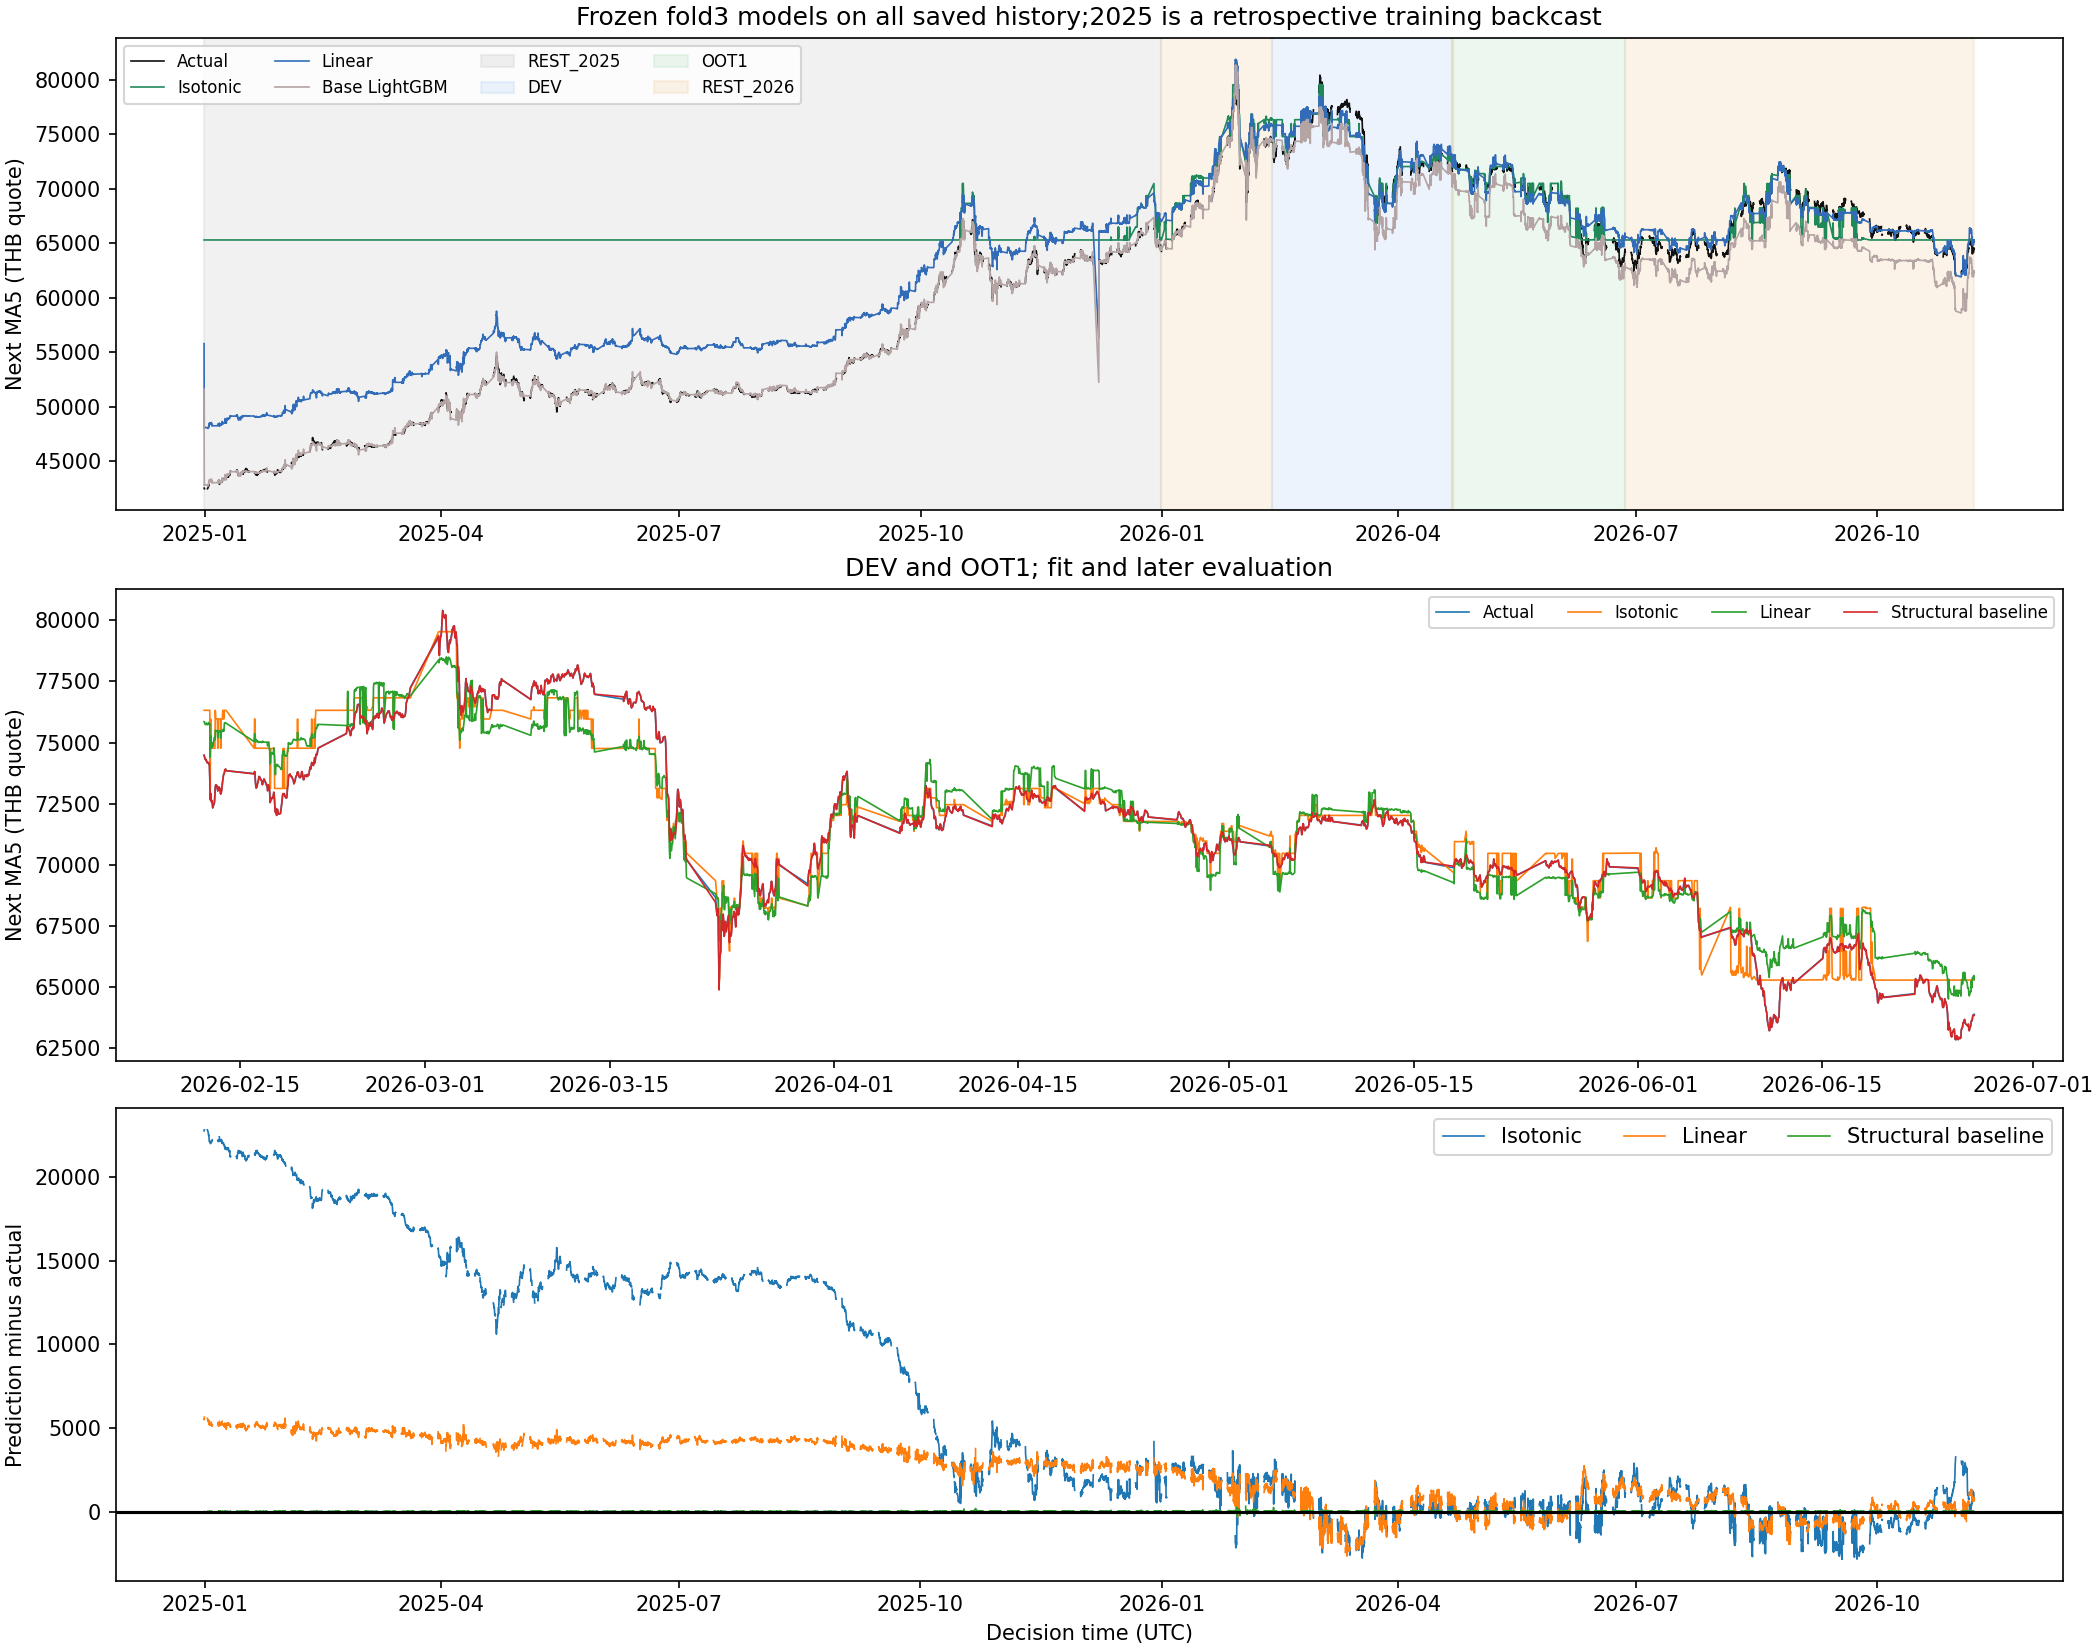

In [3]:
performance,comparison=report(package)
display(performance.query("slice_type=='period'"))
display(comparison.query("slice_type=='period' and first=='prediction_isotonic' and second=='prediction_linear'"))
display(Image(filename=str(package/'all_time_actual_prediction.png')))

## Data supplied for further local work

base_training_X_y.csv.gz contains the original matured fold3 base-training rows; calibration_dev_X_y.csv.gz fits the two existing calibrators; validation_oot1_X_y.csv.gz is their later evaluation; post_fold3_backtest_X_y.csv.gz covers later context. all_time_X_y_context.csv.gz is the complete prepared feature/target table. Use package_metadata.json and feature_schema.csv to preserve feature order and transformations. Future raw market data must first pass through the original feature pipeline. Never pass y_ma5, period, provenance, or label timestamps as X. Quantitative trading backtests need additional trading assumptions; this notebook forecasts MA5 prices only.